# Notebook 1 — The Forward Model: Simulating HDX-MS Data

**Hydrogen-Deuterium Exchange Mass Spectrometry (HDX-MS)** probes protein dynamics by
measuring how quickly backbone amide hydrogens exchange with deuterium from heavy water (D₂O).
Protected, structured regions exchange slowly; flexible, solvent-exposed regions exchange fast.

Before we can *fit* exchange rates from real data, it helps to understand the **forward model**:
given known rates, what spectra do we expect to observe?

This notebook walks through:
1. Defining a protein and counting its exchangeable amide hydrogens
2. Assigning ground-truth exchange rates
3. Generating synthetic mass spectra at each labelling timepoint
4. Visualising the isotope envelope shift and deuterium uptake curve

In [2]:
import sys
sys.path.insert(0, '../src')   # tell Python where hdxrate lives

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import hdxrate
from hdxrate.testing import generate_mock_rows
from hdxrate.spectra import theoretical_isotope_dist

print('hdxrate version:', hdxrate.__file__)

hdxrate version: /Users/allan/Work/Claude/hdxrate_v2.0/notebooks/../src/hdxrate/__init__.py


## 1. Define the protein

We use a 19-residue synthetic peptide whose sequence contains all common amino acid types
except proline. Exchangeable amide hydrogens are backbone NHs on **residues 3 and beyond**
that are not proline — residues 1–2 exchange so fast they are effectively unobservable.

In [3]:
SEQUENCE = "ACDEFGHIKLMNQRSTVWY"   # 19 residues, no proline

# Count exchangeable amide hydrogens:
#   - skip residues at index 0 and 1 (first two are not observable)
#   - skip proline (no backbone NH)
N_EXCHANGEABLE = sum(1 for i, aa in enumerate(SEQUENCE) if i >= 2 and aa != 'P')

print(f"Sequence  : {SEQUENCE}")
print(f"Length    : {len(SEQUENCE)} residues")
print(f"Exchangeable amide NH: {N_EXCHANGEABLE}")

Sequence  : ACDEFGHIKLMNQRSTVWY
Length    : 19 residues
Exchangeable amide NH: 17


## 2. Define experiment parameters

These are the experimental conditions you would set in the lab:

| Parameter | Value | Meaning |
|-----------|-------|---------|
| `timepoints` | 10 – 86400 s | Labelling durations (log-spaced) |
| `pH` | 6.0 | Solution pH (affects intrinsic exchange rates) |
| `charge` | 3 | ESI charge state of the peptide |
| `d2o_fraction` | 0.95 | Fraction of D₂O in the labelling buffer |
| `d2o_purity` | 0.95 | Isotopic purity of the D₂O |
| `temperature` | 295 K | ~22 °C, common room-temperature experiment |
| `true_backexchange` | 0.20 | 20% deuterium lost during sample workup |

In [4]:
TIMEPOINTS       = np.array([10., 60., 300., 1800., 7200., 86400.])  # seconds
PH               = 6.0
CHARGE           = 3
D2O_FRACTION     = 0.95
D2O_PURITY       = 0.95
TEMPERATURE      = 295.0   # Kelvin
TRUE_BACKEXCHANGE = 0.20   # fraction re-exchanged during workup
NUM_BINS         = 30      # mass spectrum bins

print("Timepoints (s):", TIMEPOINTS)

Timepoints (s): [1.00e+01 6.00e+01 3.00e+02 1.80e+03 7.20e+03 8.64e+04]


## 3. Assign ground-truth exchange rates

In a real experiment these are *unknown* — finding them is the goal of inference.
Here we define them explicitly so we can later check how well the model recovers them.

We use a log-linear spacing from very slow (log k = −10, half-life ~70 days)
to moderately fast (log k = −3, half-life ~14 min).

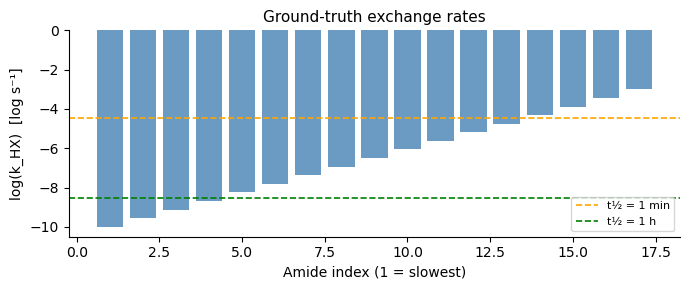

Slowest : log k = -10.0  →  t½ ≈ 0.2 days
Fastest : log k = -3.0 →  t½ ≈ 0.2 min


In [5]:
TRUE_LOG_RATES = np.linspace(-10, -3, N_EXCHANGEABLE)
TRUE_RATES     = np.exp(TRUE_LOG_RATES)    # s⁻¹

# Visualise the rate distribution
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(np.arange(1, N_EXCHANGEABLE + 1), TRUE_LOG_RATES, color='steelblue', alpha=0.8)
ax.set_xlabel('Amide index (1 = slowest)', fontsize=10)
ax.set_ylabel('log(k_HX)  [log s⁻¹]', fontsize=10)
ax.set_title('Ground-truth exchange rates', fontsize=11)
ax.axhline(np.log(0.693 / 60),  color='orange', lw=1.2, ls='--', label='t½ = 1 min')
ax.axhline(np.log(0.693 / 3600), color='green', lw=1.2, ls='--', label='t½ = 1 h')
ax.legend(fontsize=8)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Slowest : log k = {TRUE_LOG_RATES[0]:.1f}  →  t½ ≈ {0.693/TRUE_RATES[0]/86400:.1f} days")
print(f"Fastest : log k = {TRUE_LOG_RATES[-1]:.1f} →  t½ ≈ {0.693/TRUE_RATES[-1]/60:.1f} min")

## 4. Generate synthetic InputRows

`generate_mock_rows()` implements the **exact same forward model** used during inference:

1. Per-residue deuterium incorporation probability:
   `p_i(t) = (1 − exp(−k_i · t)) × D₂O_fraction × D₂O_purity × (1 − backexchange)`
2. The resulting mass spectrum is computed via the **Poisson-binomial distribution** (exact)
   convolved with the undeuterated isotope envelope from natural-abundance isotopes.
3. Small Gaussian noise is added to mimic detector noise.

The output is a list of `InputRow` objects — one per timepoint.

In [6]:
rows = generate_mock_rows(
    sequence         = SEQUENCE,
    true_log_rates   = TRUE_LOG_RATES,
    timepoints       = TIMEPOINTS,
    pHs              = [PH],
    charge           = CHARGE,
    d2o_fraction     = D2O_FRACTION,
    d2o_purity       = D2O_PURITY,
    temperature      = TEMPERATURE,
    true_backexchange= TRUE_BACKEXCHANGE,
    noise_sigma      = 0.01,
    num_bins         = NUM_BINS,
    rng_seed         = 42,
)

print(f"Generated {len(rows)} InputRows")
print("\nFirst row:")
r0 = rows[0]
print(f"  protein_id   : {r0.protein_id}")
print(f"  sequence     : {r0.sequence}")
print(f"  timepoint    : {r0.timepoint:.0f} s")
print(f"  pH           : {r0.pH}")
print(f"  charge       : {r0.charge}")
print(f"  mz shape     : {r0.mz.shape}")
print(f"  intensities  : min={r0.intensities.min():.3f}, max={r0.intensities.max():.3f}")

Generated 6 InputRows

First row:
  protein_id   : mock_protein
  sequence     : ACDEFGHIKLMNQRSTVWY
  timepoint    : 10 s
  pH           : 6.0
  charge       : 3
  mz shape     : (30,)
  intensities  : min=0.000, max=1.000


## 5. Inspect a single spectrum

Each `InputRow` holds the **m/z axis** and corresponding **relative intensities** as measured
by the mass spectrometer. The spectrum is the isotope envelope of the peptide at one timepoint.

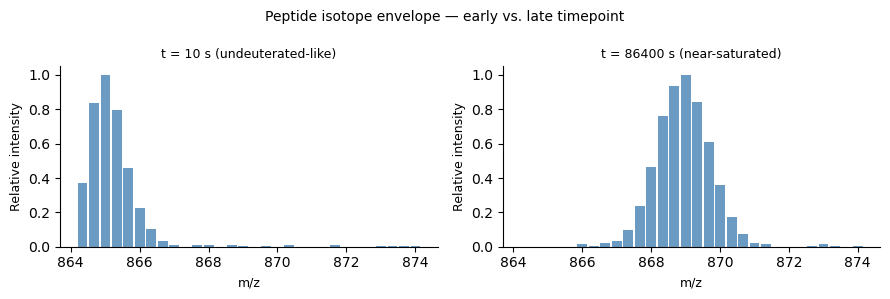

In [7]:
# Show the first and last timepoints side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 3))

for ax, row, label in zip(axes, [rows[0], rows[-1]],
                           [f't = {TIMEPOINTS[0]:.0f} s (undeuterated-like)',
                            f't = {TIMEPOINTS[-1]:.0f} s (near-saturated)']):
    ax.bar(row.mz, row.intensities, width=(row.mz[1]-row.mz[0])*0.85,
           color='steelblue', alpha=0.8)
    ax.set_xlabel('m/z', fontsize=9)
    ax.set_ylabel('Relative intensity', fontsize=9)
    ax.set_title(label, fontsize=9)
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('Peptide isotope envelope — early vs. late timepoint', fontsize=10)
plt.tight_layout()
plt.show()

## 6. Isotope envelopes across all timepoints

As labelling time increases, the centroid of the isotope distribution shifts to higher mass
because more deuterium is incorporated. The shape also broadens as exchange becomes
heterogeneous across residues.

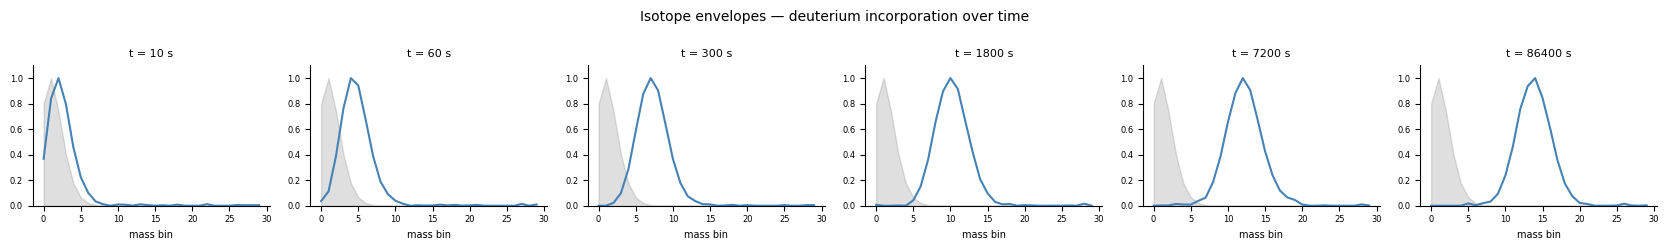

In [8]:
# Convert m/z back to mass bins (relative scale, mass = mz*charge - charge*1.007276)
# We use the bin index for a clean x-axis
n_tp   = len(rows)
n_cols = min(n_tp, 6)
n_rows = (n_tp + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.8 * n_cols, 2.5 * n_rows))
axes = np.array(axes).ravel()

# Undeuterated reference spectrum (no labelling)
undeuterated = theoretical_isotope_dist(SEQUENCE, NUM_BINS)

for i, (row, ax) in enumerate(zip(rows, axes)):
    bins = np.arange(len(row.intensities))
    # grey: undeuterated reference
    ax.fill_between(bins, 0, undeuterated[:len(bins)], alpha=0.25,
                    color='grey', label='undeuterated')
    # blue: observed at this timepoint
    ax.plot(bins, row.intensities, color='steelblue', lw=1.5,
            label=f't={row.timepoint:.0f}s')
    ax.set_title(f't = {row.timepoint:.0f} s', fontsize=8)
    ax.set_xlabel('mass bin', fontsize=7)
    ax.tick_params(labelsize=6)
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylim(0, 1.1)

for j in range(n_tp, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Isotope envelopes — deuterium incorporation over time', fontsize=10)
plt.tight_layout()
plt.show()

## 7. Deuterium uptake curve

The **centroid** of the mass distribution is a single number summarising how much deuterium
has been incorporated. Plotting centroid vs. log(time) gives the classic **deuterium uptake
curve**: it rises quickly at first (fast-exchanging residues) then levels off as only the
slowest residues remain.

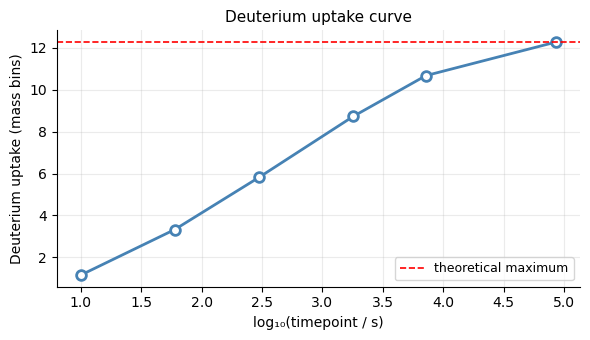

Max theoretical uptake (with backexchange): 12.3 Da


In [9]:
def centroid(dist):
    x = np.arange(len(dist))
    return np.sum(x * dist) / (np.sum(dist) + 1e-12)

centroids       = np.array([centroid(r.intensities) for r in rows])
undeuterated_c  = centroid(undeuterated[:NUM_BINS])

# Deuterium uptake = shift from undeuterated centroid
d_uptake = centroids - undeuterated_c

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.log10(TIMEPOINTS), d_uptake,
        marker='o', ms=7, lw=2, color='steelblue',
        markerfacecolor='white', markeredgewidth=2)
ax.set_xlabel('log₁₀(timepoint / s)', fontsize=10)
ax.set_ylabel('Deuterium uptake (mass bins)', fontsize=10)
ax.set_title('Deuterium uptake curve', fontsize=11)
ax.axhline(N_EXCHANGEABLE * D2O_FRACTION * D2O_PURITY * (1 - TRUE_BACKEXCHANGE),
           color='red', lw=1.2, ls='--', label='theoretical maximum')
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Max theoretical uptake (with backexchange): "
      f"{N_EXCHANGEABLE * D2O_FRACTION * D2O_PURITY * (1 - TRUE_BACKEXCHANGE):.1f} Da")

## Summary

We have:
- Defined a 19-residue protein with **17 exchangeable amide NHs**
- Assigned ground-truth log-rates spanning slow (buried) to fast (exposed) residues
- Generated synthetic mass spectra at 6 timepoints using the exact forward model
- Observed the characteristic **rightward shift** of the isotope envelope with time
- Plotted the **deuterium uptake curve** showing saturation at long times

**Next:** In Notebook 2 we feed these synthetic rows into the Bayesian inference engine
and see how well it recovers the true rates.